# spec-trait Evaluation

Analysis of runtime performance, compile time, and binary size for `spec!`/`when` vs alternatives:
- **spec**: compile-time specialization via `spec!`/`when` macros
- **dyn**: trait object dynamic dispatch
- **enum**: enum-based dispatch
- **generic**: generic fallback (no specialization)
- **runtime_typeid**: `TypeId`-based runtime branching

## Examples
| # | Operation | Key specialization |
|---|-----------|--------------------|
| ex01 | Histogram | u8 array[256] vs HashMap |
| ex02 | Set intersection | u8 bitmap[256] vs HashSet |
| ex03 | Contains search | u8 memchr SIMD |
| ex04 | Sort | u8 counting sort |
| ex05 | Distinct count | u8 bitmap[256] vs HashSet |
| ex06 | Bulk serialize | u8 zero-copy |
| ex07 | Dedup | u8 bitmap vs HashSet |
| ex08 | Count value | u8 memchr_iter vs filter |

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
import numpy as np
from pathlib import Path

sns.set_theme(style="whitegrid", font_scale=1.1)
RESULTS = Path("../results")

APPROACH_ORDER = ["spec", "enum", "runtime_typeid", "naive"]
APPROACH_COLORS = {
    "spec": "#2ca02c",
    "enum": "#1f77b4",
    "runtime_typeid": "#d62728",
    "naive": "#9467bd",
}

## 1. Runtime Performance

In [2]:
rt = pd.read_csv(RESULTS / "runtime.csv")
rt["size"] = pd.to_numeric(rt["size"], errors="coerce")
rt = rt.dropna(subset=["size", "median_ns"])
rt["median_us"] = rt["median_ns"] / 1000.0
rt.head()

,example,operation,group,approach,size,mean_ns,median_ns,std_error_ns,median_us
0,ex01,extend,ex01_extend,enum,1024,32.353081,32.243272,0.095472,0.032243
1,ex01,extend,ex01_extend,enum,16384,189.383627,188.248457,0.505191,0.188248
2,ex01,extend,ex01_extend,enum,256,22.624483,22.677729,0.052502,0.022678
3,ex01,extend,ex01_extend,enum,4096,58.884218,58.804625,0.099535,0.058805
4,ex01,extend,ex01_extend,enum,65536,1053.673100,1052.401776,2.504792,1.052402


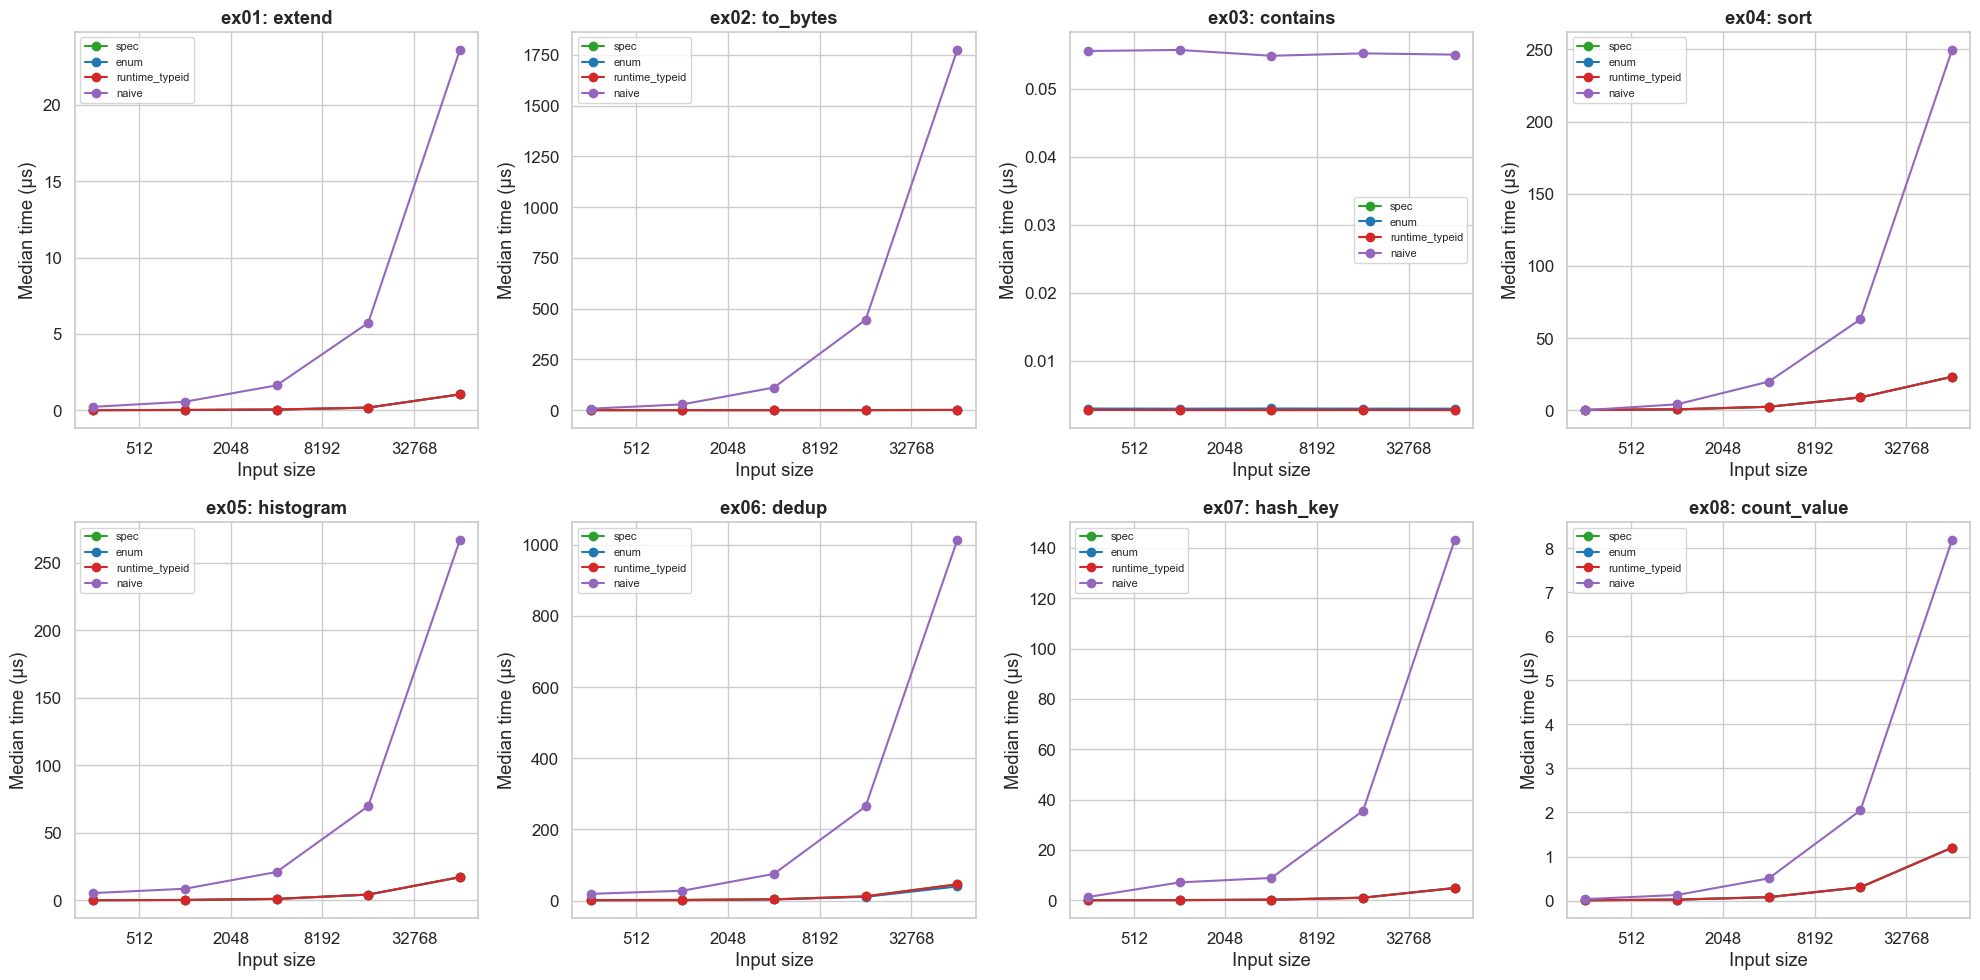

In [3]:
examples = sorted(rt["example"].unique())
n_ex = len(examples)
fig, axes = plt.subplots(2, (n_ex + 1) // 2, figsize=(5 * ((n_ex + 1) // 2), 10), sharey=False)
axes = axes.flatten()

for idx, ex in enumerate(examples):
    ax = axes[idx]
    sub = rt[rt["example"] == ex]
    op = sub["operation"].iloc[0]
    for approach in APPROACH_ORDER:
        d = sub[sub["approach"] == approach].sort_values("size")
        if d.empty:
            continue
        ax.plot(d["size"], d["median_us"], marker="o", label=approach,
                color=APPROACH_COLORS.get(approach, "gray"))
    ax.set_title(f"{ex}: {op}", fontweight="bold")
    ax.set_xlabel("Input size")
    ax.set_ylabel("Median time (\u00b5s)")
    ax.set_xscale("log", base=2)
    ax.xaxis.set_major_formatter(ticker.ScalarFormatter())
    ax.legend(fontsize=8)

for idx in range(n_ex, len(axes)):
    axes[idx].set_visible(False)

plt.tight_layout()
plt.savefig(RESULTS / "runtime_all.pdf", bbox_inches="tight")
plt.show()

### Speedup of `spec` over each alternative (at largest size)

In [4]:
largest = rt.groupby(["example", "approach"]).apply(
    lambda g: g.loc[g["size"].idxmax()]
).reset_index(drop=True)

spec_times = largest[largest["approach"] == "spec"][["example", "median_ns"]].rename(
    columns={"median_ns": "spec_ns"}
)
merged = largest.merge(spec_times, on="example")
merged["speedup_vs_spec"] = merged["median_ns"] / merged["spec_ns"]

pivot = merged.pivot_table(index="example", columns="approach", values="speedup_vs_spec")
pivot = pivot[[c for c in APPROACH_ORDER if c in pivot.columns]]
pivot.style.format("{:.2f}x").background_gradient(cmap="RdYlGn", axis=None)

/var/folders/85/w1f_3bln5rzbljrg0v33t7880000gn/T/ipykernel_72415/1433551797.py:1: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  largest = rt.groupby(["example", "approach"]).apply(


approach,spec,enum,runtime_typeid,naive
example,,,,
ex01,1.00x,1.00x,1.00x,22.44x
ex02,1.00x,1.01x,0.99x,1663.60x
ex03,1.00x,1.07x,1.00x,19.90x
ex04,1.00x,0.99x,0.99x,10.70x
ex05,1.00x,0.99x,0.99x,15.41x
ex06,1.00x,0.86x,0.99x,21.97x
ex07,1.00x,1.01x,1.01x,29.52x
ex08,1.00x,1.00x,1.00x,6.81x


## 2. Compile Time

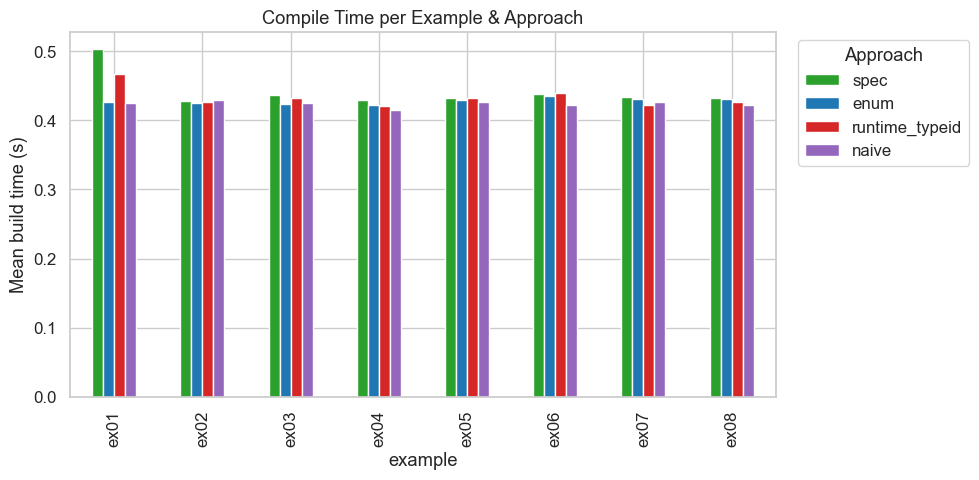

In [5]:
bt = pd.read_csv(RESULTS / "build_time.csv")
bt_avg = bt.groupby(["example", "variant"])["build_time_secs"].mean().reset_index()
bt_avg.columns = ["example", "approach", "mean_build_secs"]

fig, ax = plt.subplots(figsize=(10, 5))
bt_pivot = bt_avg.pivot(index="example", columns="approach", values="mean_build_secs")
bt_pivot = bt_pivot[[c for c in APPROACH_ORDER if c in bt_pivot.columns]]
bt_pivot.plot(kind="bar", ax=ax, color=[APPROACH_COLORS.get(c, "gray") for c in bt_pivot.columns])
ax.set_ylabel("Mean build time (s)")
ax.set_title("Compile Time per Example & Approach")
ax.legend(title="Approach", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(RESULTS / "build_time.pdf", bbox_inches="tight")
plt.show()

## 3. Binary Size

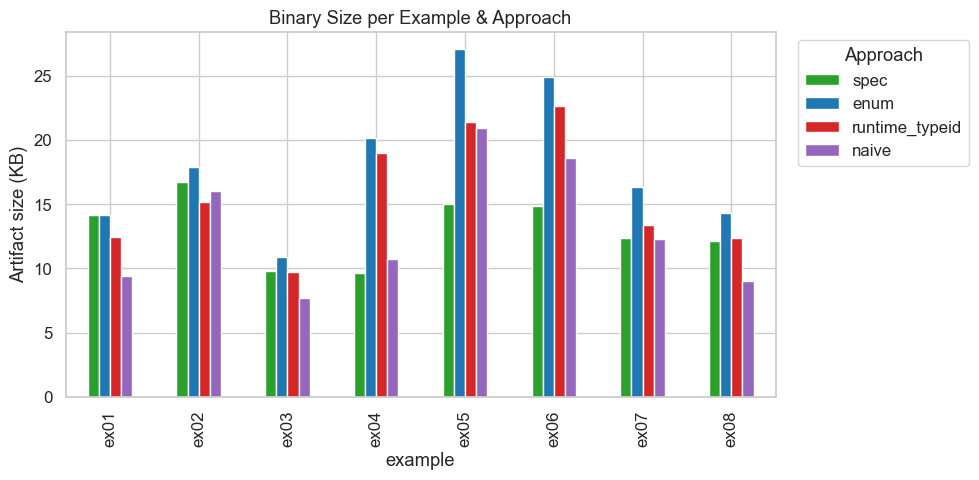

In [6]:
bs = pd.read_csv(RESULTS / "binary_size.csv")
bs.columns = ["example", "approach", "binary_size_bytes", "stripped_size_bytes"]
bs["size_kb"] = bs["binary_size_bytes"] / 1024.0

fig, ax = plt.subplots(figsize=(10, 5))
bs_pivot = bs.pivot(index="example", columns="approach", values="size_kb")
bs_pivot = bs_pivot[[c for c in APPROACH_ORDER if c in bs_pivot.columns]]
bs_pivot.plot(kind="bar", ax=ax, color=[APPROACH_COLORS.get(c, "gray") for c in bs_pivot.columns])
ax.set_ylabel("Artifact size (KB)")
ax.set_title("Binary Size per Example & Approach")
ax.legend(title="Approach", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(RESULTS / "binary_size.pdf", bbox_inches="tight")
plt.show()

## 4. Summary Table

In [7]:
# Combine all metrics into a single summary
summary_parts = []

# Runtime speedup at largest size
if 'pivot' in dir():
    rt_summary = pivot.mean().rename("mean_speedup_vs_spec")
    summary_parts.append(rt_summary)

# Build time overhead vs spec
if 'bt_avg' in dir():
    spec_bt = bt_avg[bt_avg["approach"] == "spec"][["example", "mean_build_secs"]].rename(
        columns={"mean_build_secs": "spec_build"}
    )
    bt_merged = bt_avg.merge(spec_bt, on="example")
    bt_merged["build_ratio"] = bt_merged["mean_build_secs"] / bt_merged["spec_build"]
    bt_ratio = bt_merged.groupby("approach")["build_ratio"].mean()
    summary_parts.append(bt_ratio.rename("mean_build_ratio_vs_spec"))

# Binary size overhead vs spec
if 'bs' in dir():
    spec_bs = bs[bs["approach"] == "spec"][["example", "binary_size_bytes"]].rename(
        columns={"binary_size_bytes": "spec_size"}
    )
    bs_merged = bs.merge(spec_bs, on="example")
    bs_merged["size_ratio"] = bs_merged["binary_size_bytes"] / bs_merged["spec_size"]
    bs_ratio = bs_merged.groupby("approach")["size_ratio"].mean()
    summary_parts.append(bs_ratio.rename("mean_size_ratio_vs_spec"))

if summary_parts:
    summary = pd.concat(summary_parts, axis=1)
    summary = summary.loc[[a for a in APPROACH_ORDER if a in summary.index]]
    summary.style.format("{:.2f}").background_gradient(cmap="RdYlGn_r", axis=0)